# DS2 clustering

Checks whether DS2 patients form natural groups without using the risk level, and whether those groups match the 5 risk levels. Four methods are compared: k-means, hierarchical, Gaussian mixture and DBSCAN. Input is the processed training set from `DS2_Data_Preprocessing.ipynb`.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

RANDOM_STATE = 42

## 1. Load the processed training set

In [22]:
train = pd.read_csv("../../../../assets/datasets/2_KG_Kidney_Disease_Dataset/processed/train.csv")
X = train.drop(columns=["Target"])
y = train["Target"]
short = ["None", "Low", "Mod", "High", "Severe"]

sample = train.sample(3000, random_state=RANDOM_STATE)
X_s = sample.drop(columns=["Target"])
y_s = sample["Target"]
print(X.shape, X_s.shape)

(16430, 42) (3000, 42)


**Observation:**
- Target is only used to compare with the clusters, never to fit them
- Four methods with different ideas of a cluster: k-means (groups around a centre), hierarchical (a tree of merges), Gaussian mixture (soft, oval groups) and DBSCAN (dense regions, outliers as noise)
- Hierarchical clustering, DBSCAN and silhouette scores use a 3,000-row sample, as their cost grows with the square of the rows

## 2. Look for structure with PCA

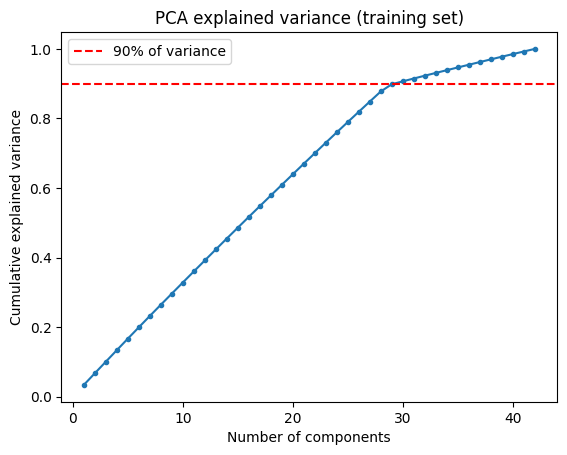

Components for 90%: 30 of 42


In [23]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axhline(0.9, color="red", linestyle="--", label="90% of variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.legend()
plt.show()
print("Components for 90%:", (cum < 0.9).sum() + 1, "of", X.shape[1])

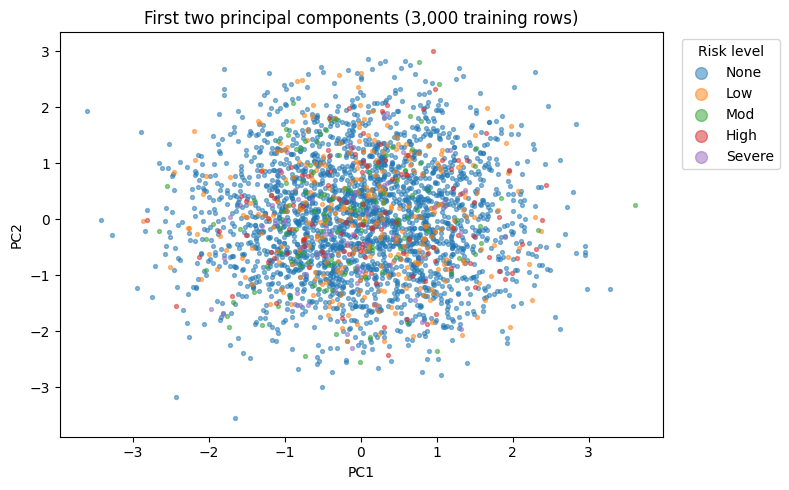

In [24]:
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit(X).transform(X_s)

fig, ax = plt.subplots(figsize=(8, 5))
for k, s in enumerate(short):
    m = (y_s == k).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=s)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Risk level", markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("First two principal components (3,000 training rows)")
fig.tight_layout()
plt.show()

**Observation:**
- 30 of 42 components are needed for 90% of the variance, and each adds about the same share, so there is no simple low-dimensional structure
- After about 28 components the rest mostly carry the 0/1 features, which have less variance than the scaled numeric features
- Risk levels overlap completely in the first two components

## 3. Hierarchical clustering

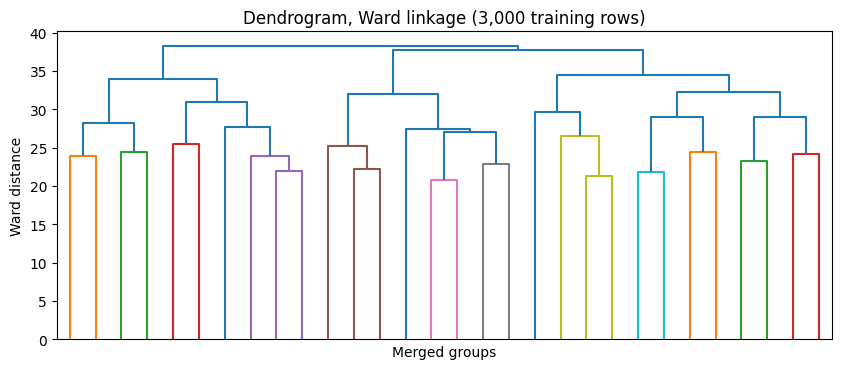

In [25]:
Z = linkage(X_s, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.xlabel("Merged groups")
plt.ylabel("Ward distance")
plt.title("Dendrogram, Ward linkage (3,000 training rows)")
plt.show()

**Observation:**
- The dendrogram merges at similar heights with no long gap, so there is no clear number of clusters

## 4. Choose the number of clusters

In [26]:
ks = range(2, 9)
km_models = {k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X) for k in ks}
gmm_labels = {k: GaussianMixture(k, covariance_type="diag", random_state=RANDOM_STATE).fit(X).predict(X_s) for k in ks}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), [km_models[k].inertia_ for k in ks], marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_title("k-means elbow")

sil = pd.DataFrame({
    "k-means": [silhouette_score(X_s, km_models[k].predict(X_s)) for k in ks],
    "Hierarchical": [silhouette_score(X_s, AgglomerativeClustering(k, linkage="ward").fit_predict(X_s)) for k in ks],
    "Gaussian mixture": [silhouette_score(X_s, gmm_labels[k]) for k in ks],
}, index=ks)
sil.plot(marker="o", ax=axes[1])
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score by number of clusters")
fig.tight_layout()
plt.show()
display(sil.round(3) + 0.0)

KeyboardInterrupt: 

**Observation:**
- The k-means elbow curve falls smoothly with no clear bend
- Silhouette scores are close to 0 for every method and number of clusters (best about 0.02), so points are as close to other clusters as to their own

## 5. DBSCAN

In [16]:
dist = np.sort(NearestNeighbors(n_neighbors=5).fit(X_s).kneighbors(X_s)[0][:, -1])
rows = []
for p in [10, 25, 50, 75, 90]:
    eps = np.percentile(dist, p)
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_s)
    rows.append({
        "eps percentile": p,
        "eps": round(eps, 2),
        "Clusters": len(set(labels)) - (-1 in labels),
        "Noise %": round((labels == -1).mean() * 100, 1),
        "Adjusted Rand index": round(adjusted_rand_score(y_s, labels), 3) + 0.0,
    })
display(pd.DataFrame(rows).set_index("eps percentile"))
print("Distance to 5th nearest neighbour:", round(dist.min(), 2), "to", round(dist.max(), 2))

,eps,Clusters,Noise %,Adjusted Rand index
eps percentile,,,,
10,5.31,32,65.9,-0.001
25,5.45,6,37.9,-0.003
50,5.62,1,14.6,-0.010
75,5.79,1,4.4,0.007
90,5.95,1,1.1,-0.002


Distance to 5th nearest neighbour: 4.79 to 6.62


**Observation:**
- eps is taken from percentiles of each point's distance to its 5th nearest neighbour
- These distances are almost the same for every point (about 4.8 to 6.6), a typical effect of many dimensions, so DBSCAN jumps from mostly noise to one big cluster
- No setting gives groups that match the risk levels (Adjusted Rand index about 0)

## 6. Compare clusters with the risk level

,Adjusted Rand index,Silhouette
k-means,0.000,0.019
Hierarchical,0.001,0.000
Gaussian mixture,-0.001,0.011


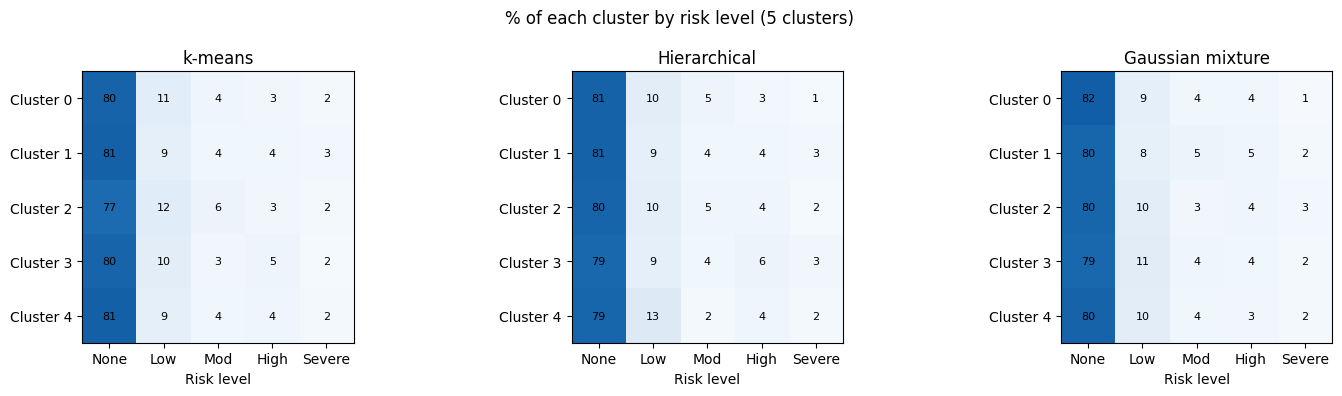

In [17]:
labels = {
    "k-means": km_models[5].predict(X_s),
    "Hierarchical": AgglomerativeClustering(5, linkage="ward").fit_predict(X_s),
    "Gaussian mixture": gmm_labels[5],
}
display(pd.DataFrame({
    "Adjusted Rand index": [adjusted_rand_score(y_s, l) for l in labels.values()],
    "Silhouette": [silhouette_score(X_s, l) for l in labels.values()],
}, index=list(labels)).round(3) + 0.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, l) in zip(axes, labels.items()):
    mix = pd.crosstab(l, y_s, normalize="index").mul(100)
    ax.imshow(mix, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(short)), short)
    ax.set_yticks(range(len(mix)), [f"Cluster {i}" for i in mix.index])
    for i in range(mix.shape[0]):
        for j in range(mix.shape[1]):
            ax.text(j, i, f"{mix.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("Risk level")
    ax.set_title(name)
fig.suptitle("% of each cluster by risk level (5 clusters)")
fig.tight_layout()
plt.show()

**Observation:**
- 5 clusters are used to match the 5 risk levels
- Adjusted Rand index is about 0 for every method, so no clusters match the risk levels
- Every cluster has about the same risk mix as the whole data (around 80% No Disease, shown as None)
- This agrees with the preprocessing findings: DS2 has no natural groups linked to risk

## 7. Clusters vs real labels

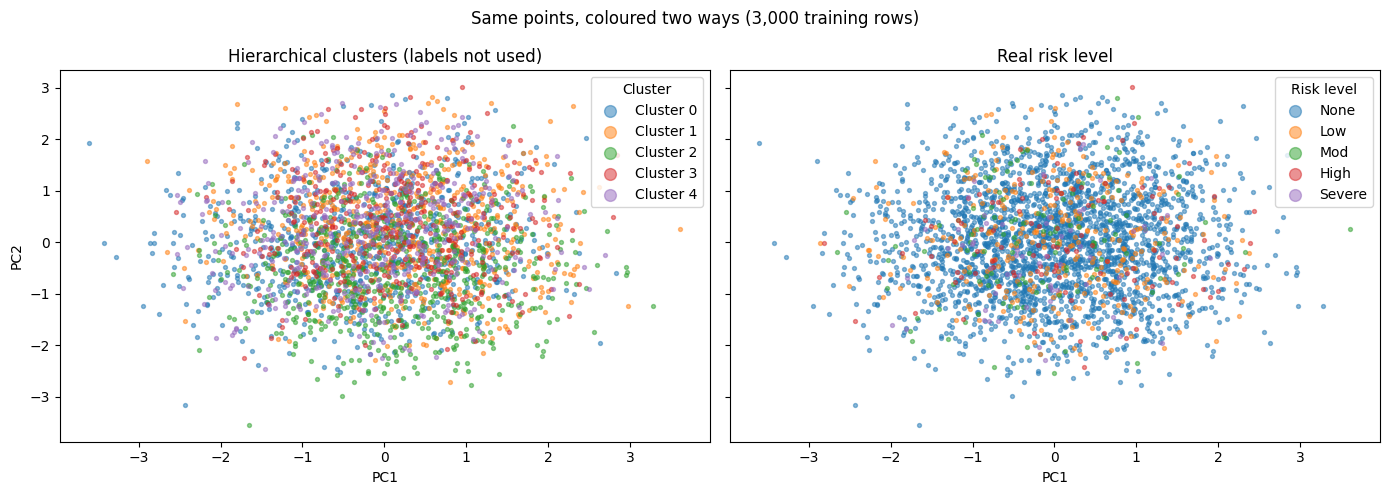

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for k in pd.crosstab(labels["Hierarchical"], y_s).idxmax(axis=1).sort_values().index:
    m = labels["Hierarchical"] == k
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=f"Cluster {k}")
for k, s in enumerate(short):
    m = (y_s == k).values
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.5, label=s)
axes[0].set_title("Hierarchical clusters (labels not used)")
axes[1].set_title("Real risk level")
for ax, t in zip(axes, ["Cluster", "Risk level"]):
    ax.set_xlabel("PC1")
    ax.legend(title=t, markerscale=3)
axes[0].set_ylabel("PC2")
fig.suptitle("Same points, coloured two ways (3,000 training rows)")
fig.tight_layout()
plt.show()

**Observation:**
- 

## 8. Check different feature groups

In [19]:
binary = [c for c in X.columns if X[c].nunique() <= 2]
continuous = [c for c in X.columns if X[c].nunique() > 6]
groups = {
    "All features": list(X.columns),
    "Without 0/1 features": [c for c in X.columns if c not in binary],
    "Continuous only": continuous,
    "0/1 features only": binary,
}
display(pd.DataFrame({
    "Features": [len(cols) for cols in groups.values()],
    "Adjusted Rand index": [
        round(adjusted_rand_score(y_s, AgglomerativeClustering(5, linkage="ward").fit_predict(X_s[cols])), 3) + 0.0
        for cols in groups.values()
    ],
}, index=list(groups)))

,Features,Adjusted Rand index
All features,42,0.001
Without 0/1 features,29,0.000
Continuous only,26,0.005
0/1 features only,13,0.000


**Observation:**
- 

## 9. Summary and limitations

- 